# ML10 RNN

In [1]:
# !pip uninstall -y torch torchvision torchaudio
# !pip install torch torchvision torchaudio

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from collections import Counter
import math
import warnings
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED = 21
torch.manual_seed(SEED)
np.random.seed(SEED)

# Введение

### a) Задачи, в которых полезны RNN
Рекуррентные нейронные сети предназначены для работы с последовательными данными, где важен порядок элементов и существуют временные или контекстные зависимости. Типичные задачи:
- **Языковое моделирование и генерация текста**: предсказание следующего токена на основе предыдux (чат-боты, автодополнение, креативная генерация текста).
- **Классификация последовательностей**: присвоение метки всей последовательности (анализ тональности, обнаружение спама, определение языка).
- **Разметка последовательностей (Sequence tagging)**: присвоение метки каждому элементу последовательности (POS-тегирование, извлечение именованных сущностей - NER).
- **Последовательность-в-последовательность (Seq2Seq)**: преобразование одной последовательности в другую (машинный перевод, распознавание речи, суммаризация).
- **Прогнозирование временных рядов**: предсказание будущих значений временного сигнала (цены на акции, погода, спрос).
- **Генерация музыки и аудио**: моделирование последовательностей нот или спектрограмм.

### b) Формулировки задач с примерами

**Один-ко-многим** (один вход -> последовательность на выходе):
1. Генерация подписей к изображениям (image captioning): изображение -> последовательность слов, описывающих его.
2. Генерация текста из начального слова (seed): один промпт/токен -> сгенерированное предложение.

**Многие-ко-многим (синхронно)** (последовательность на входе -> последовательность той же длины на выходе):
1. POS-тегирование: последовательность слов -> последовательность меток частей речи.
2. Классификация видео по кадрам: последовательность кадров -> последовательность меток для каждого кадра.

**Многие-ко-многим (энкодер-декодер, разная длина)** (последовательность на входе -> последовательность другой длины на выходе):
1. Машинный перевод: предложение на английском -> предложение на французском.
2. Суммаризация: длинная статья -> краткое содержание.

**Многие-к-одному** (последовательность на входе -> один выход):
1. Анализ тональности: отзыв -> метка "положительный/отрицательный".
2. Классификация пола по имени: последовательность букв -> мужской/женский.

### c) Обработка слова "Hello" RNN для классификации языка
Модель читает слово посимвольно. На каждом шаге `t` она получает эмбеддинг текущего символа `x_t` и предыдущее скрытое состояние `h_{t-1}`, формируя новое скрытое состояние `h_t`. После последнего символа финальное скрытое состояние подается в классификатор (линейный слой + softmax), который выдает вероятности языков.

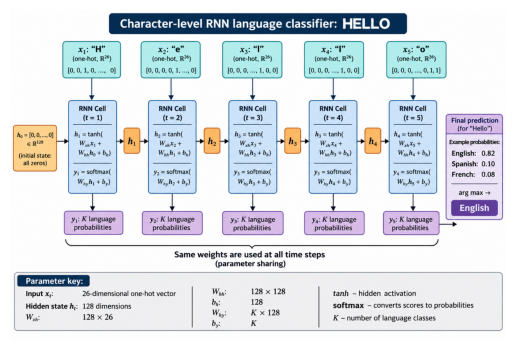

In [3]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread('/content/hello.png')
plt.imshow(img)
plt.axis('off')
plt.show()

### d) Vanilla RNN против LSTM против GRU
- **Vanilla RNN (классическая RNN)**: одно скрытое состояние, обновление `h_t = tanh(W_xh x_t + W_hh h_{t-1} + b)`. Страдает от проблемы затухающих/взрывающихся градиентов, поскольку одна и та же матрица весов применяется многократно во времени.
- **LSTM**: вводит состояние ячейки `c_t` (долгосрочная память) и три гейта (входной, забывания, выходной). Состояние ячейки обновляется аддитивно, что позволяет градиентам течь через множество временных шагов без затухания. Больше параметров, выше выразительная способность.
- **GRU**: упрощенная версия LSTM с двумя гейтами (сброса и обновления) и без отдельного состояния ячейки (скрытое состояние выполняет обе роли). Меньше параметров, чем у LSTM, часто сравнимое качество, обучается быстрее.

Уравнения GRU:
- `r_t = sigmoid(W_xr x_t + W_hr h_{t-1} + b_r)` (гейт сброса)
- `z_t = sigmoid(W_xz x_t + W_hz h_{t-1} + b_z)` (гейт обновления)
- `h_tilde = tanh(W_xh x_t + W_hh (r_t * h_{t-1}) + b_h)` (кандидат)
- `h_t = (1 - z_t) * h_{t-1} + z_t * h_tilde`

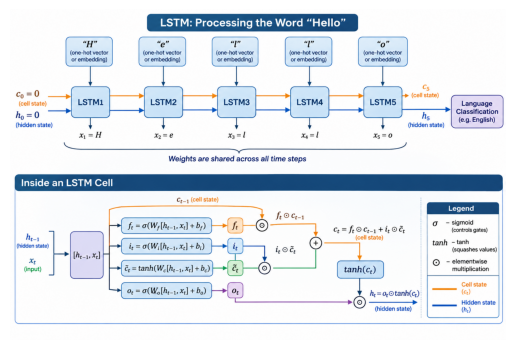

In [4]:
img = mpimg.imread('/content/lstm.png')
plt.imshow(img)
plt.axis('off')
plt.show()

# Анализ данных

In [5]:
df = pd.read_csv('/content/babynames-clean.csv', header=None, names=['name', 'gender'])
print('Shape:', df.shape)
print('Columns:', df.columns.tolist())
df.head()

Shape: (6782, 2)
Columns: ['name', 'gender']


,name,gender
0,John,boy
1,William,boy
2,James,boy
3,Charles,boy
4,George,boy


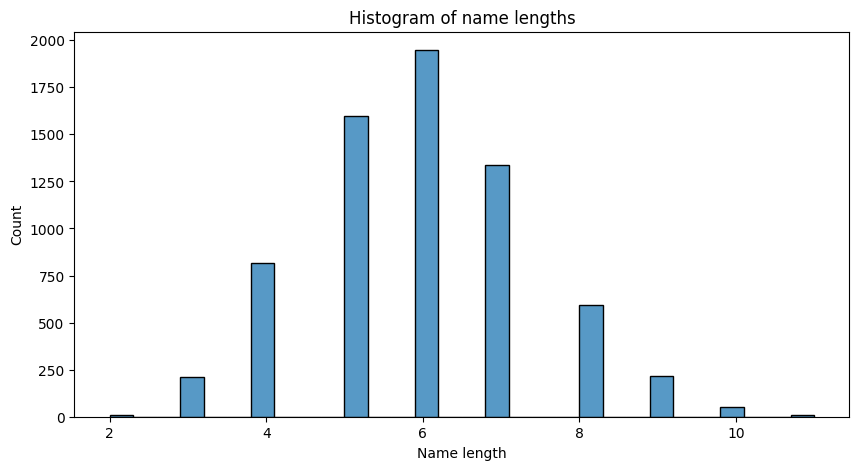

Mean length: 5.928339722795635
Median length: 6.0
Mode length: 6


In [6]:
df['name_len'] = df['name'].str.len()
plt.figure(figsize=(10, 5))
sns.histplot(df['name_len'], bins=30, kde=False)
plt.title('Histogram of name lengths')
plt.xlabel('Name length')
plt.ylabel('Count')
plt.show()
print('Mean length:', df['name_len'].mean())
print('Median length:', df['name_len'].median())
print('Mode length:', df['name_len'].mode()[0])

gender
boy     3437
girl    3345
Name: count, dtype: int64


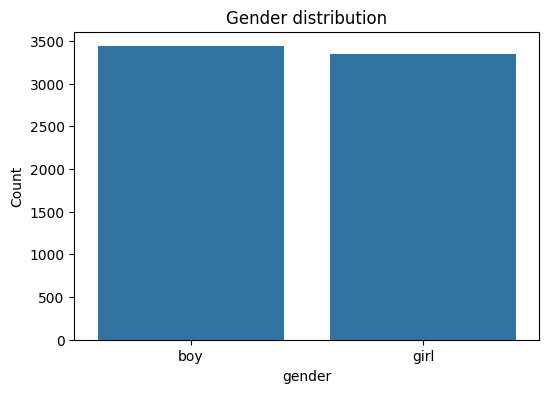

Imbalance ratio (max/min): 1.03


In [7]:
gender_counts = df['gender'].value_counts()
print(gender_counts)
plt.figure(figsize=(6, 4))
sns.barplot(x=gender_counts.index, y=gender_counts.values)
plt.title('Gender distribution')
plt.ylabel('Count')
plt.show()
ratio = gender_counts.max() / gender_counts.min()
print(f'Imbalance ratio (max/min): {ratio:.2f}')

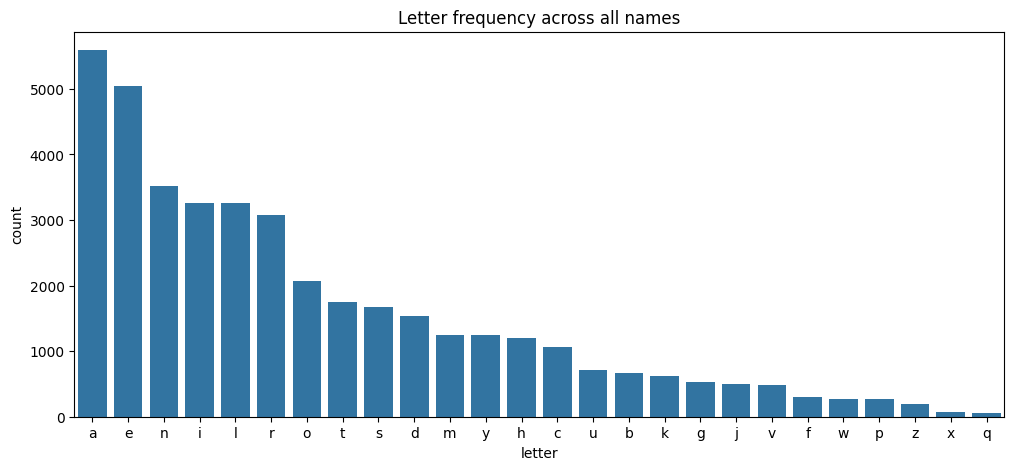

,letter,count,freq
7,a,5593,0.139109
9,e,5038,0.125305
3,n,3524,0.087649
5,i,3264,0.081182
6,l,3255,0.080958
12,r,3070,0.076357
1,o,2071,0.051510
17,t,1745,0.043401
10,s,1674,0.041636
20,d,1532,0.038104


In [8]:
all_letters = ''.join(df['name'].str.lower().tolist())
letter_freq = Counter(all_letters)
total = sum(letter_freq.values())
freq_df = pd.DataFrame([(k, v, v/total) for k, v in letter_freq.items()],
                       columns=['letter', 'count', 'freq'])
freq_df = freq_df.sort_values('count', ascending=False)
plt.figure(figsize=(12, 5))
sns.barplot(data=freq_df, x='letter', y='count')
plt.title('Letter frequency across all names')
plt.show()
freq_df.head(10)

# Предобработка данных

In [9]:
df['gender_enc'] = (df['gender'].map({'boy': 0, 'girl': 1})).astype(int)
df['name'] = df['name'].str.lower()

SOS = '^'
EOS = '$'
PAD = ' '

df['processed'] = df['name'].apply(lambda n: SOS + n + EOS)
max_len = df['processed'].str.len().max()
df['padded'] = df['processed'].apply(lambda s: s + PAD * (max_len - len(s)))
print('Max padded length:', max_len)

Max padded length: 13


In [10]:
all_chars = set()
for s in df['padded']:
    all_chars.update(list(s))
tokens = sorted(list(all_chars))
token2id = {t: i for i, t in enumerate(tokens)}
id2token = {i: t for t, i in token2id.items()}
vocab_size = len(tokens)
print('Vocab size:', vocab_size)
print('Tokens:', tokens)

Vocab size: 29
Tokens: [' ', '$', '^', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


In [11]:
def encode(s):
    return [token2id[c] for c in s]

X = np.array([encode(s) for s in df['padded'].values])
y_gender = df['gender_enc'].values
print('X shape:', X.shape)

X shape: (6782, 13)


In [12]:
idx = np.arange(len(X))
idx_train, idx_tmp = train_test_split(idx, test_size=0.2, random_state=SEED, stratify=y_gender)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.5, random_state=SEED, stratify=y_gender[idx_tmp])

X_train, y_train = X[idx_train], y_gender[idx_train]
X_val, y_val = X[idx_val], y_gender[idx_val]
X_test, y_test = X[idx_test], y_gender[idx_test]
print('Train/Val/Test:', len(X_train), len(X_val), len(X_test))

Train/Val/Test: 5425 678 679


In [13]:
class NamesDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, i):
        return self.X[i], self.y[i]

BATCH_SIZE = 128
train_ds = NamesDataset(X_train, y_train)
val_ds = NamesDataset(X_val, y_val)
test_ds = NamesDataset(X_test, y_test)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE)

# Реализация Vanilla RNN

In [14]:
class VanillaRNNCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.W_xh = nn.Parameter(torch.empty(input_size, hidden_size))
        self.W_hh = nn.Parameter(torch.empty(hidden_size, hidden_size))
        self.b_h = nn.Parameter(torch.zeros(hidden_size))
        nn.init.xavier_uniform_(self.W_xh)
        nn.init.xavier_uniform_(self.W_hh)

    def forward(self, x, h):
        return torch.tanh(x @ self.W_xh + h @ self.W_hh + self.b_h)


class NameRNN(nn.Module):
    def __init__(self, vocab_size, emb_size, hidden_size, pad_id):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_size, padding_idx=pad_id)
        self.rnn = VanillaRNNCell(emb_size, hidden_size)
        self.hidden_size = hidden_size
        self.token_head = nn.Linear(hidden_size, vocab_size)
        self.gender_head = nn.Linear(hidden_size, 1)
        self.pad_id = pad_id

    def init_hidden(self, batch_size):
        return torch.zeros(batch_size, self.hidden_size, device=self.emb.weight.device)

    def forward(self, x, mode='lm'):
        B, T = x.shape
        h = self.init_hidden(B)
        token_logits = []
        for t in range(T):
            e = self.emb(x[:, t])
            h = self.rnn(e, h)
            token_logits.append(self.token_head(h))
        token_logits = torch.stack(token_logits, dim=1)
        last_h = h
        gender_logit = self.gender_head(last_h).squeeze(-1)
        if mode == 'lm':
            return token_logits
        if mode == 'gender':
            return gender_logit
        return token_logits, gender_logit

In [15]:
def train_lm(model, train_loader, val_loader, epochs=15, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    pad_id = model.pad_id
    history = {'train': [], 'val': []}
    for ep in range(epochs):
        model.train()
        losses = []
        for xb, _ in train_loader:
            xb = xb.to(device)
            logits = model(xb, mode='lm')
            inp = xb[:, :-1]
            tgt = xb[:, 1:]
            logits = logits[:, :-1, :]
            mask = (tgt != pad_id)
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)),
                                   tgt.reshape(-1), reduction='none')
            loss = (loss * mask.reshape(-1)).sum() / mask.sum().clamp(min=1)
            opt.zero_grad()
            loss.backward()
            opt.step()
            losses.append(loss.item())
        history['train'].append(np.mean(losses))

        model.eval()
        vloss = []
        with torch.no_grad():
            for xb, _ in val_loader:
                xb = xb.to(device)
                logits = model(xb, mode='lm')[:, :-1, :]
                tgt = xb[:, 1:]
                mask = (tgt != pad_id)
                loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)),
                                       tgt.reshape(-1), reduction='none')
                loss = (loss * mask.reshape(-1)).sum() / mask.sum().clamp(min=1)
                vloss.append(loss.item())
        history['val'].append(np.mean(vloss))
        print(f'Epoch {ep+1}/{epochs} | train_loss={history["train"][-1]:.4f} | val_loss={history["val"][-1]:.4f}')
    return history

In [16]:
EMB_SIZE = 32
HIDDEN_SIZE = 64
PAD_ID = token2id[PAD]

rnn_lm = NameRNN(vocab_size, EMB_SIZE, HIDDEN_SIZE, PAD_ID).to(device)
hist_rnn_lm = train_lm(rnn_lm, train_loader, val_loader, epochs=15, lr=2e-3)

Epoch 1/15 | train_loss=2.7680 | val_loss=2.4747
Epoch 2/15 | train_loss=2.3583 | val_loss=2.3270
Epoch 3/15 | train_loss=2.2651 | val_loss=2.2659
Epoch 4/15 | train_loss=2.2119 | val_loss=2.2261
Epoch 5/15 | train_loss=2.1768 | val_loss=2.2014
Epoch 6/15 | train_loss=2.1512 | val_loss=2.1853
Epoch 7/15 | train_loss=2.1271 | val_loss=2.1705
Epoch 8/15 | train_loss=2.1081 | val_loss=2.1559
Epoch 9/15 | train_loss=2.0944 | val_loss=2.1473
Epoch 10/15 | train_loss=2.0792 | val_loss=2.1341
Epoch 11/15 | train_loss=2.0685 | val_loss=2.1290
Epoch 12/15 | train_loss=2.0566 | val_loss=2.1162
Epoch 13/15 | train_loss=2.0460 | val_loss=2.1148
Epoch 14/15 | train_loss=2.0370 | val_loss=2.1191
Epoch 15/15 | train_loss=2.0285 | val_loss=2.1026


In [17]:
@torch.no_grad()
def generate_names(model, n=10, prefix=SOS, temperature=1.0, max_steps=max_len):
    model.eval()
    out_names = []
    for _ in range(n):
        ids = [token2id[c] for c in prefix]
        for _ in range(max_steps):
            x = torch.tensor([ids], dtype=torch.long, device=device)
            logits = model(x, mode='lm')[:, -1, :]
            probs = F.softmax(logits / temperature, dim=-1).cpu().numpy()[0]
            next_id = np.random.choice(len(probs), p=probs)
            ids.append(next_id)
            if id2token[next_id] == EOS:
                break
        name = ''.join(id2token[i] for i in ids[1:] if id2token[i] not in (EOS, PAD)).strip()
        out_names.append(name)
    return out_names

print('Temperature 0.8:', generate_names(rnn_lm, 10, temperature=0.8))
print('Temperature 1.5:', generate_names(rnn_lm, 10, temperature=1.5))

Temperature 0.8: ['alma', 'aller', 'salishie', 'gollyn', 'celie', 'corsell', 'gretton', 'shanna', 'deshera', 'pernik']
Temperature 1.5: ['come', 'motes', 'heonikra', 'shiubq', 'kers', 'brodlaivinand', '', 'meniicke', 'prrelevol', 'chaqhabdole']


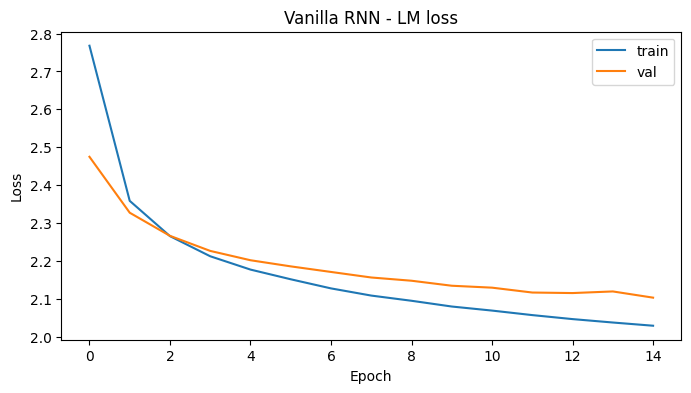

In [18]:
plt.figure(figsize=(8, 4))
plt.plot(hist_rnn_lm['train'], label='train')
plt.plot(hist_rnn_lm['val'], label='val')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Vanilla RNN - LM loss')
plt.legend()
plt.show()

In [19]:
@torch.no_grad()
def predict_gender_proba(model, loader):
    model.eval()
    ys, ps = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        logit = model(xb, mode='gender')
        p = torch.sigmoid(logit).cpu().numpy()
        ps.append(p)
        ys.append(yb.numpy())
    return np.concatenate(ys), np.concatenate(ps)

y_true, y_prob = predict_gender_proba(rnn_lm, test_loader)
print('RNN LM ROC AUC (gender on test):', roc_auc_score(y_true, y_prob))

RNN LM ROC AUC (gender on test): 0.38510933703575145


# GRU

In [20]:
class NameGRU(nn.Module):
    def __init__(self, vocab_size, emb_size, hidden_size, pad_id):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_size, padding_idx=pad_id)
        self.rnn = nn.GRU(emb_size, hidden_size, batch_first=True)
        self.hidden_size = hidden_size
        self.token_head = nn.Linear(hidden_size, vocab_size)
        self.gender_head = nn.Linear(hidden_size, 1)
        self.pad_id = pad_id

    def forward(self, x, mode='lm'):
        e = self.emb(x)
        out, h = self.rnn(e)
        token_logits = self.token_head(out)
        last_h = h.squeeze(0)
        gender_logit = self.gender_head(last_h).squeeze(-1)
        if mode == 'lm':
            return token_logits
        if mode == 'gender':
            return gender_logit
        return token_logits, gender_logit

gru_lm = NameGRU(vocab_size, EMB_SIZE, HIDDEN_SIZE, PAD_ID).to(device)
hist_gru_lm = train_lm(gru_lm, train_loader, val_loader, epochs=15, lr=2e-3)

Epoch 1/15 | train_loss=2.8012 | val_loss=2.5085
Epoch 2/15 | train_loss=2.3775 | val_loss=2.3324
Epoch 3/15 | train_loss=2.2673 | val_loss=2.2621
Epoch 4/15 | train_loss=2.2099 | val_loss=2.2196
Epoch 5/15 | train_loss=2.1696 | val_loss=2.1887
Epoch 6/15 | train_loss=2.1363 | val_loss=2.1633
Epoch 7/15 | train_loss=2.1107 | val_loss=2.1450
Epoch 8/15 | train_loss=2.0847 | val_loss=2.1280
Epoch 9/15 | train_loss=2.0672 | val_loss=2.1088
Epoch 10/15 | train_loss=2.0461 | val_loss=2.0990
Epoch 11/15 | train_loss=2.0315 | val_loss=2.0908
Epoch 12/15 | train_loss=2.0145 | val_loss=2.0815
Epoch 13/15 | train_loss=2.0003 | val_loss=2.0719
Epoch 14/15 | train_loss=1.9899 | val_loss=2.0646
Epoch 15/15 | train_loss=1.9763 | val_loss=2.0571


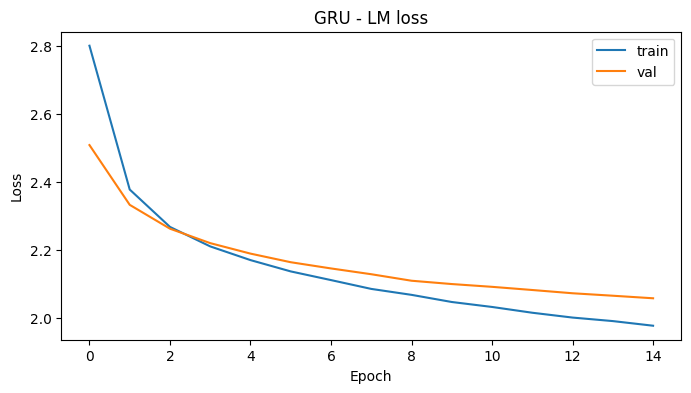

GRU samples: ['adbella', 'reemen', 'sherle', 'vincy', 'gulmy', 'dtetco', 'andie', 'ruphell', 'brda', 'hard']
GRU LM ROC AUC (gender on test): 0.4694637278722666


In [21]:
plt.figure(figsize=(8, 4))
plt.plot(hist_gru_lm['train'], label='train')
plt.plot(hist_gru_lm['val'], label='val')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('GRU - LM loss')
plt.legend()
plt.show()
print('GRU samples:', generate_names(gru_lm, 10, temperature=0.8))
y_true, y_prob = predict_gender_proba(gru_lm, test_loader)
print('GRU LM ROC AUC (gender on test):', roc_auc_score(y_true, y_prob))

# LSTM

In [22]:
class NameLSTM(nn.Module):
    def __init__(self, vocab_size, emb_size, hidden_size, pad_id):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_size, padding_idx=pad_id)
        self.rnn = nn.LSTM(emb_size, hidden_size, batch_first=True)
        self.hidden_size = hidden_size
        self.token_head = nn.Linear(hidden_size, vocab_size)
        self.gender_head = nn.Linear(hidden_size, 1)
        self.pad_id = pad_id

    def forward(self, x, mode='lm'):
        e = self.emb(x)
        out, (h, c) = self.rnn(e)
        token_logits = self.token_head(out)
        last_h = h.squeeze(0)
        gender_logit = self.gender_head(last_h).squeeze(-1)
        if mode == 'lm':
            return token_logits
        if mode == 'gender':
            return gender_logit
        return token_logits, gender_logit

lstm_lm = NameLSTM(vocab_size, EMB_SIZE, HIDDEN_SIZE, PAD_ID).to(device)
hist_lstm_lm = train_lm(lstm_lm, train_loader, val_loader, epochs=15, lr=2e-3)

Epoch 1/15 | train_loss=2.8661 | val_loss=2.5757
Epoch 2/15 | train_loss=2.4455 | val_loss=2.3884
Epoch 3/15 | train_loss=2.3090 | val_loss=2.3000
Epoch 4/15 | train_loss=2.2449 | val_loss=2.2570
Epoch 5/15 | train_loss=2.2026 | val_loss=2.2207
Epoch 6/15 | train_loss=2.1680 | val_loss=2.1970
Epoch 7/15 | train_loss=2.1413 | val_loss=2.1798
Epoch 8/15 | train_loss=2.1186 | val_loss=2.1580
Epoch 9/15 | train_loss=2.0978 | val_loss=2.1440
Epoch 10/15 | train_loss=2.0793 | val_loss=2.1277
Epoch 11/15 | train_loss=2.0640 | val_loss=2.1156
Epoch 12/15 | train_loss=2.0478 | val_loss=2.1047
Epoch 13/15 | train_loss=2.0336 | val_loss=2.0932
Epoch 14/15 | train_loss=2.0222 | val_loss=2.0836
Epoch 15/15 | train_loss=2.0080 | val_loss=2.0803


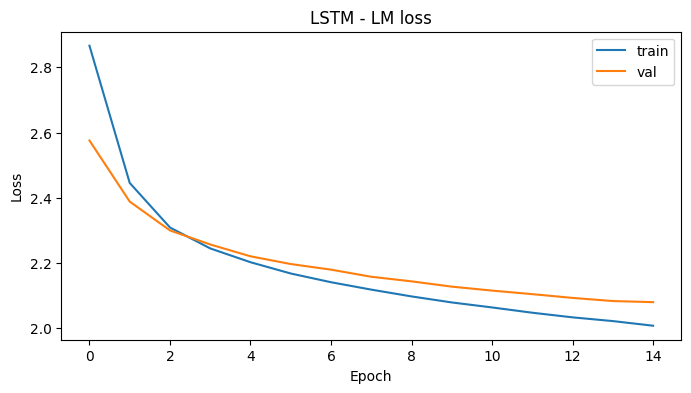

LSTM samples: ['arnle', 'jemal', 'mabelle', 'desy', 'jaylee', 'stwran', 'wirston', 'misale', 'hoylo', 'ibberley']
LSTM LM ROC AUC (gender on test): 0.4068639361332871


In [23]:
plt.figure(figsize=(8, 4))
plt.plot(hist_lstm_lm['train'], label='train')
plt.plot(hist_lstm_lm['val'], label='val')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('LSTM - LM loss')
plt.legend()
plt.show()
print('LSTM samples:', generate_names(lstm_lm, 10, temperature=0.8))
y_true, y_prob = predict_gender_proba(lstm_lm, test_loader)
print('LSTM LM ROC AUC (gender on test):', roc_auc_score(y_true, y_prob))

# Сравнение моделей

### a) Предлагаемая метрика: **Unique Realistic Ratio (URR)** (Доля уникальных реалистичных имен)
Сгенерировать N имен, посчитать, сколько из них (i) уникальны и (ii) присутствуют в исходном обучающем корпусе. URR = количество_уникальных_и_реальных / N. Эта метрика отражает как разнообразие, так и соответствие распределению данных.

### b) `ytixelprep` задом наперед — это `perplexity` (перплексия).

### c) Связь перплексии и кросс-энтропии:
`CE = - (1/N) * sum_i log p_i`
`Perplexity = exp(CE) = exp(- (1/N) * sum_i log p_i) = (prod_i p_i)^(-1/N)`

### d) Реализация перплексии напрямую и через кросс-энтропию (представлена в коде ниже).

In [24]:
@torch.no_grad()
def eval_perplexity(model, loader):
    model.eval()
    pad_id = model.pad_id
    total_loss = 0.0
    total_tokens = 0
    for xb, _ in loader:
        xb = xb.to(device)
        logits = model(xb, mode='lm')[:, :-1, :]
        tgt = xb[:, 1:]
        mask = (tgt != pad_id)
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)),
                               tgt.reshape(-1), reduction='none')
        total_loss += (loss * mask.reshape(-1)).sum().item()
        total_tokens += mask.sum().item()
    ce = total_loss / max(total_tokens, 1)
    return ce, math.exp(ce)

for name, m in [('RNN', rnn_lm), ('GRU', gru_lm), ('LSTM', lstm_lm)]:
    ce, ppl = eval_perplexity(m, val_loader)
    print(f'{name}: CE={ce:.4f}, Perplexity={ppl:.4f}')

RNN: CE=2.0935, Perplexity=8.1135
GRU: CE=2.0473, Perplexity=7.7473
LSTM: CE=2.0736, Perplexity=7.9532


In [25]:
letter_probs = freq_df.set_index('letter')['freq'].to_dict()
uniform_probs = {t: 1.0/vocab_size for t in tokens}

def ppl_from_probs(probs_dict, sequences):
    log_sum = 0.0
    n = 0
    for seq in sequences:
        for c in seq:
            p = probs_dict.get(c, 1e-10)
            log_sum += math.log(p)
            n += 1
    ce = -log_sum / max(n, 1)
    return math.exp(ce)

train_names = df.loc[idx_train, 'padded'].tolist()
print('Random (uniform) model perplexity:', ppl_from_probs(uniform_probs, train_names))
print('Most-popular-letters model perplexity:', ppl_from_probs(letter_probs, train_names))

Random (uniform) model perplexity: 29.000000000006132
Most-popular-letters model perplexity: 1005840.3327552503


# Классификация пола

In [26]:
def train_gender(model, train_loader, val_loader, epochs=15, lr=1e-3, loss_type='bce'):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train': [], 'val': []}
    for ep in range(epochs):
        model.train()
        losses = []
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            logit = model(xb, mode='gender')
            if loss_type == 'bce':
                loss = F.binary_cross_entropy_with_logits(logit, yb)
            else:
                probs = torch.sigmoid(logit)
                probs = torch.stack([1 - probs, probs], dim=1).clamp(1e-8, 1-1e-8)
                target = yb.long()
                loss = F.nll_loss(torch.log(probs), target)
            opt.zero_grad()
            loss.backward()
            opt.step()
            losses.append(loss.item())
        history['train'].append(np.mean(losses))

        model.eval()
        vloss = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logit = model(xb, mode='gender')
                if loss_type == 'bce':
                    loss = F.binary_cross_entropy_with_logits(logit, yb)
                else:
                    probs = torch.sigmoid(logit)
                    probs = torch.stack([1 - probs, probs], dim=1).clamp(1e-8, 1-1e-8)
                    loss = F.nll_loss(torch.log(probs), yb.long())
                vloss.append(loss.item())
        history['val'].append(np.mean(vloss))
        print(f'Epoch {ep+1}/{epochs} | train_loss={history["train"][-1]:.4f} | val_loss={history["val"][-1]:.4f}')
    return history

In [27]:
rnn_g_bce = NameRNN(vocab_size, EMB_SIZE, HIDDEN_SIZE, PAD_ID).to(device)
hist_rnn_g_bce = train_gender(rnn_g_bce, train_loader, val_loader, epochs=10, loss_type='bce')

rnn_g_nll = NameRNN(vocab_size, EMB_SIZE, HIDDEN_SIZE, PAD_ID).to(device)
hist_rnn_g_nll = train_gender(rnn_g_nll, train_loader, val_loader, epochs=10, loss_type='nll')

Epoch 1/10 | train_loss=0.6012 | val_loss=0.4646
Epoch 2/10 | train_loss=0.4720 | val_loss=0.4204
Epoch 3/10 | train_loss=0.4305 | val_loss=0.3960
Epoch 4/10 | train_loss=0.4117 | val_loss=0.4121
Epoch 5/10 | train_loss=0.4044 | val_loss=0.3922
Epoch 6/10 | train_loss=0.3868 | val_loss=0.3848
Epoch 7/10 | train_loss=0.3712 | val_loss=0.3737
Epoch 8/10 | train_loss=0.3566 | val_loss=0.3805
Epoch 9/10 | train_loss=0.3482 | val_loss=0.3772
Epoch 10/10 | train_loss=0.3341 | val_loss=0.3869
Epoch 1/10 | train_loss=0.5931 | val_loss=0.4844
Epoch 2/10 | train_loss=0.4692 | val_loss=0.4386
Epoch 3/10 | train_loss=0.4302 | val_loss=0.4099
Epoch 4/10 | train_loss=0.4164 | val_loss=0.4136
Epoch 5/10 | train_loss=0.4012 | val_loss=0.3984
Epoch 6/10 | train_loss=0.3826 | val_loss=0.3917
Epoch 7/10 | train_loss=0.3668 | val_loss=0.4154
Epoch 8/10 | train_loss=0.3601 | val_loss=0.4163
Epoch 9/10 | train_loss=0.3427 | val_loss=0.4078
Epoch 10/10 | train_loss=0.3343 | val_loss=0.4076


### e) Какая функция потерь лучше?
Для бинарной классификации пола с одним логитом и сигмоидной активацией предпочтительнее использовать **BCE (Binary Cross Entropy with logits)**. Она численно стабильна (объединяет sigmoid + log), напрямую оптимизирована для одного выхода и имеет хорошо ведущие себя градиенты. NLL, применяемая путем ручного стекинга `[1-p, p]` и взятия `log`, математически эквивалентна в пределе больших данных, но менее численно стабильна и более многословна. Для многоклассовой классификации пола (если расширять задачу) естественным выбором будет NLL с softmax.

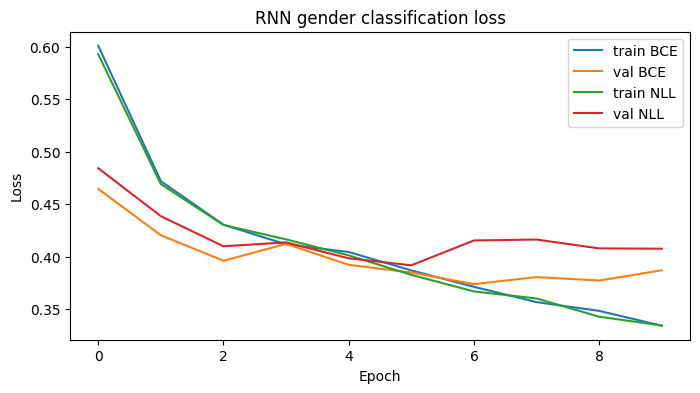

RNN-BCE ROC AUC: 0.9026466504685874
RNN-NLL ROC AUC: 0.9069680666435266


In [28]:
plt.figure(figsize=(8, 4))
plt.plot(hist_rnn_g_bce['train'], label='train BCE')
plt.plot(hist_rnn_g_bce['val'], label='val BCE')
plt.plot(hist_rnn_g_nll['train'], label='train NLL')
plt.plot(hist_rnn_g_nll['val'], label='val NLL')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('RNN gender classification loss')
plt.legend(); plt.show()

for name, m in [('RNN-BCE', rnn_g_bce), ('RNN-NLL', rnn_g_nll)]:
    yt, yp = predict_gender_proba(m, test_loader)
    print(name, 'ROC AUC:', roc_auc_score(yt, yp))

In [29]:
gru_g = NameGRU(vocab_size, EMB_SIZE, HIDDEN_SIZE, PAD_ID).to(device)
hist_gru_g = train_gender(gru_g, train_loader, val_loader, epochs=10, loss_type='bce')

lstm_g = NameLSTM(vocab_size, EMB_SIZE, HIDDEN_SIZE, PAD_ID).to(device)
hist_lstm_g = train_gender(lstm_g, train_loader, val_loader, epochs=10, loss_type='bce')

for name, m in [('GRU', gru_g), ('LSTM', lstm_g)]:
    yt, yp = predict_gender_proba(m, test_loader)
    print(name, 'ROC AUC:', roc_auc_score(yt, yp))

Epoch 1/10 | train_loss=0.6514 | val_loss=0.5518
Epoch 2/10 | train_loss=0.5240 | val_loss=0.4504
Epoch 3/10 | train_loss=0.4581 | val_loss=0.4153
Epoch 4/10 | train_loss=0.4267 | val_loss=0.3973
Epoch 5/10 | train_loss=0.4186 | val_loss=0.4055
Epoch 6/10 | train_loss=0.4088 | val_loss=0.3871
Epoch 7/10 | train_loss=0.3994 | val_loss=0.3787
Epoch 8/10 | train_loss=0.3926 | val_loss=0.3932
Epoch 9/10 | train_loss=0.3828 | val_loss=0.3790
Epoch 10/10 | train_loss=0.3778 | val_loss=0.3811
Epoch 1/10 | train_loss=0.6592 | val_loss=0.5804
Epoch 2/10 | train_loss=0.5246 | val_loss=0.4554
Epoch 3/10 | train_loss=0.4795 | val_loss=0.4149
Epoch 4/10 | train_loss=0.4466 | val_loss=0.3961
Epoch 5/10 | train_loss=0.4312 | val_loss=0.3875
Epoch 6/10 | train_loss=0.4180 | val_loss=0.3886
Epoch 7/10 | train_loss=0.4106 | val_loss=0.3915
Epoch 8/10 | train_loss=0.3989 | val_loss=0.3903
Epoch 9/10 | train_loss=0.3985 | val_loss=0.4145
Epoch 10/10 | train_loss=0.3911 | val_loss=0.3858
GRU ROC AUC: 0.906

# Затухающий градиент

In [30]:
mode_len = int(df['name_len'].mode()[0])
df_fixed = df[df['name_len'] == mode_len].copy()
print('Mode length:', mode_len, 'subset size:', len(df_fixed))

X_fixed = np.array([encode(s) for s in df_fixed['padded'].values])
y_fixed = df_fixed['gender_enc'].values
Xf_tr, Xf_va, yf_tr, yf_va = train_test_split(X_fixed, y_fixed, test_size=0.2, random_state=SEED, stratify=y_fixed)
tr_ds = NamesDataset(Xf_tr, yf_tr)
va_ds = NamesDataset(Xf_va, yf_va)
tr_loader = DataLoader(tr_ds, batch_size=1, shuffle=True)
va_loader = DataLoader(va_ds, batch_size=1)

Mode length: 6 subset size: 1948


In [31]:
def collect_embedding_grads(model, loader, epochs=3):
    grads = []
    captured = []

    def hook(module, grad_in, grad_out):
        captured.append(grad_out[0].detach().clone())

    handle = model.emb.register_full_backward_hook(hook)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)

    for ep in range(epochs):
        ep_grads = []
        model.train()
        for xb, yb in loader:
            captured.clear()
            xb, yb = xb.to(device), yb.to(device)
            logit = model(xb, mode='gender')
            loss = F.binary_cross_entropy_with_logits(logit, yb)
            opt.zero_grad()
            loss.backward()
            opt.step()

            if captured:
                if len(captured) == 1:
                    g = captured[0]  # (B, T, emb_size)
                else:
                    g = torch.stack(captured, dim=1)  # (B, T, emb_size)
                ep_grads.append(g.cpu().numpy())

        if ep_grads:
            # Убираем лишнее измерение B=1
            ep_grads_stacked = np.stack(ep_grads, axis=0).squeeze(1)  # (num_batches, T, emb_size)
            grads.append(ep_grads_stacked)

    handle.remove()
    return np.stack(grads, axis=0)  # (epochs, num_batches, T, emb_size)

In [32]:
g_rnn = collect_embedding_grads(rnn_g_bce, tr_loader, epochs=3)

g = g_rnn[0, 0]
norms = np.linalg.norm(g, axis=-1)
print('Shape after norm over last dim:', norms.shape)
xb_sample, _ = next(iter(tr_loader))
xb_sample = xb_sample.to(device).numpy()[0]
print('Tokens in sample:', [id2token[i] for i in xb_sample])
print('Gradient norms per position:', norms)
print('Positions with non-zero gradient:', np.where(norms.flatten() > 1e-8)[0])

Shape after norm over last dim: (13,)
Tokens in sample: ['^', 'g', 'e', 'r', 't', 'i', 'e', '$', ' ', ' ', ' ', ' ', ' ']
Gradient norms per position: [0.0096932  0.01472133 0.01742133 0.02103381 0.02300676 0.02004581
 0.02451938 0.01601629 0.01042387 0.01064654 0.00772055 0.00593514
 0.00340231]
Positions with non-zero gradient: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]


In [33]:
def frobenius_by_epoch_token(grad_tensor):
    E, B, T, D = grad_tensor.shape
    frob = np.linalg.norm(grad_tensor, axis=3).mean(axis=1)
    return frob

def collect_and_summarize(ModelCls, loader, epochs=3):
    m = ModelCls(vocab_size, EMB_SIZE, HIDDEN_SIZE, PAD_ID).to(device)
    g = collect_embedding_grads(m, loader, epochs=epochs)
    frob = frobenius_by_epoch_token(g)
    mean_over_epochs = frob.mean(axis=0)
    return mean_over_epochs

mean_rnn = collect_and_summarize(NameRNN, tr_loader, epochs=3)
mean_gru = collect_and_summarize(NameGRU, tr_loader, epochs=3)
mean_lstm = collect_and_summarize(NameLSTM, tr_loader, epochs=3)

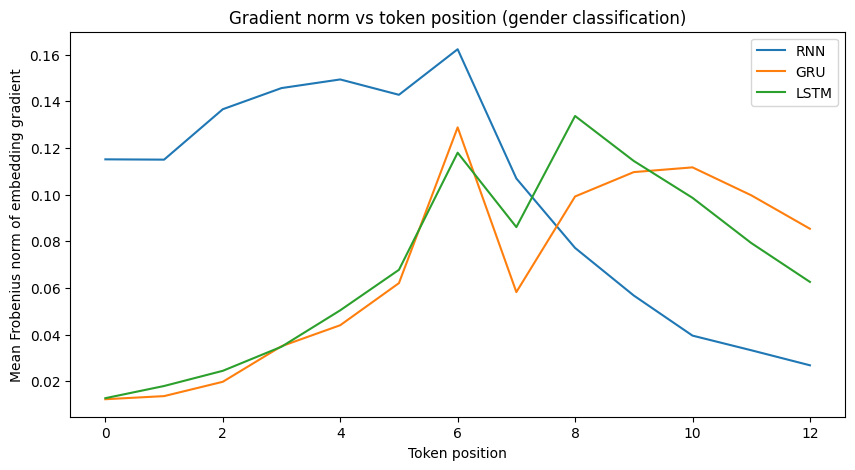

In [34]:
plt.figure(figsize=(10, 5))
plt.plot(mean_rnn, label='RNN')
plt.plot(mean_gru, label='GRU')
plt.plot(mean_lstm, label='LSTM')
plt.xlabel('Token position')
plt.ylabel('Mean Frobenius norm of embedding gradient')
plt.title('Gradient norm vs token position (gender classification)')
plt.legend(); plt.show()

### g) Повторение для задачи предсказания следующей буквы

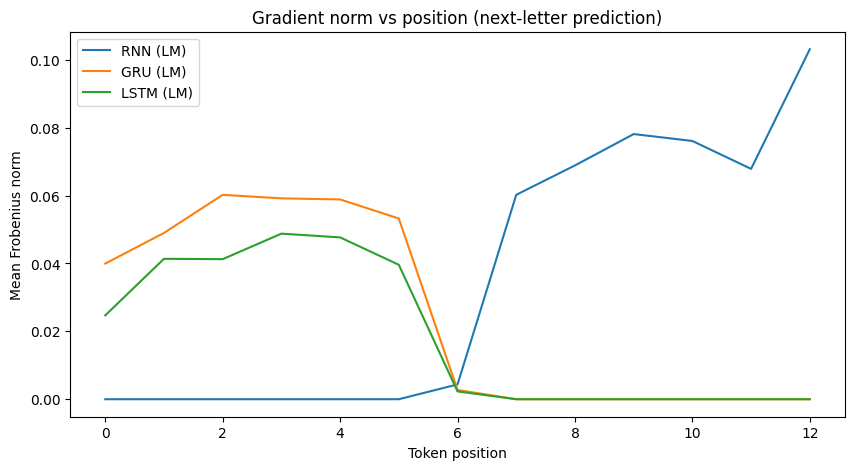

In [35]:
def collect_embedding_grads_lm(model, loader, epochs=3):
    grads = []
    captured = []

    def hook(module, grad_in, grad_out):
        captured.append(grad_out[0].detach().clone())

    handle = model.emb.register_full_backward_hook(hook)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    pad_id = model.pad_id

    for ep in range(epochs):
        ep_grads = []
        model.train()
        for xb, _ in loader:
            captured.clear()
            xb = xb.to(device)
            logits = model(xb, mode='lm')[:, :-1, :]
            tgt = xb[:, 1:]
            mask = (tgt != pad_id)
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)),
                                   tgt.reshape(-1), reduction='none')
            loss = (loss * mask.reshape(-1)).sum() / mask.sum().clamp(min=1)
            opt.zero_grad()
            loss.backward()
            opt.step()

            if captured:
                # Для VanillaRNN: len(captured) == T, каждый (B, emb_size)
                # Для GRU/LSTM: len(captured) == 1, форма (B, T, emb_size)
                if len(captured) == 1:
                    g = captured[0]
                else:
                    g = torch.stack(captured, dim=1)  # (B, T, emb_size)
                ep_grads.append(g.cpu().numpy())

        if ep_grads:
            # Убираем размерность B=1, чтобы получить (num_batches, T, emb_size)
            ep_grads_stacked = np.stack(ep_grads, axis=0).squeeze(1)
            grads.append(ep_grads_stacked)

    handle.remove()
    return np.stack(grads, axis=0)  # (epochs, num_batches, T, emb_size)

def summarize_lm(ModelCls, loader, epochs=3):
    m = ModelCls(vocab_size, EMB_SIZE, HIDDEN_SIZE, PAD_ID).to(device)
    g = collect_embedding_grads_lm(m, loader, epochs=epochs)
    frob = frobenius_by_epoch_token(g)
    return frob.mean(axis=0)

mean_rnn_lm = summarize_lm(NameRNN, tr_loader, epochs=3)
mean_gru_lm = summarize_lm(NameGRU, tr_loader, epochs=3)
mean_lstm_lm = summarize_lm(NameLSTM, tr_loader, epochs=3)

plt.figure(figsize=(10, 5))
plt.plot(mean_rnn_lm, label='RNN (LM)')
plt.plot(mean_gru_lm, label='GRU (LM)')
plt.plot(mean_lstm_lm, label='LSTM (LM)')
plt.xlabel('Token position')
plt.ylabel('Mean Frobenius norm')
plt.title('Gradient norm vs position (next-letter prediction)')
plt.legend(); plt.show()

### h) Почему используется подвыборка фиксированной длины?
Требуется, чтобы тензор градиентов имел форму `(n_epochs, max_name_length, n_tokens, embedding_size)`. При именах переменной длины каждый образец вносит вклад в градиенты на разных позициях, что делает тензор "рваным" (ragged) и невозможным для стекинга в регулярный массив. Ограничиваясь именами модальной длины, мы гарантируем, что каждый образец имеет одинаковую длину последовательности, поэтому градиенты выравниваются по батчу, и тензор имеет согласованную форму. Это также позволяет изолировать влияние позиции в последовательности от влияния самой длины последовательности.

# Многозадачное обучение

In [36]:
def train_multitask(model, train_loader, val_loader, epochs=15, lr=1e-3, alpha=0.5):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    pad_id = model.pad_id
    hist = {'train_lm': [], 'train_g': [], 'val_lm': [], 'val_g': []}
    for ep in range(epochs):
        model.train()
        lm_losses, g_losses = [], []
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            tok_logits, g_logit = model(xb, mode='both')
            inp = xb[:, :-1]; tgt = xb[:, 1:]
            logits = tok_logits[:, :-1, :]
            mask = (tgt != pad_id)
            lm_loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)),
                                      tgt.reshape(-1), reduction='none')
            lm_loss = (lm_loss * mask.reshape(-1)).sum() / mask.sum().clamp(min=1)
            g_loss = F.binary_cross_entropy_with_logits(g_logit, yb)
            loss = alpha * lm_loss + (1 - alpha) * g_loss
            opt.zero_grad()
            loss.backward()
            opt.step()
            lm_losses.append(lm_loss.item()); g_losses.append(g_loss.item())
        hist['train_lm'].append(np.mean(lm_losses))
        hist['train_g'].append(np.mean(g_losses))

        model.eval()
        vlm, vg = [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                tok_logits, g_logit = model(xb, mode='both')
                tgt = xb[:, 1:]
                logits = tok_logits[:, :-1, :]
                mask = (tgt != pad_id)
                lm_loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)),
                                          tgt.reshape(-1), reduction='none')
                lm_loss = (lm_loss * mask.reshape(-1)).sum() / mask.sum().clamp(min=1)
                g_loss = F.binary_cross_entropy_with_logits(g_logit, yb)
                vlm.append(lm_loss.item()); vg.append(g_loss.item())
        hist['val_lm'].append(np.mean(vlm))
        hist['val_g'].append(np.mean(vg))
        print(f'Epoch {ep+1}/{epochs} | lm={hist["train_lm"][-1]:.4f}/{hist["val_lm"][-1]:.4f} | g={hist["train_g"][-1]:.4f}/{hist["val_g"][-1]:.4f}')
    return hist

gru_mt = NameGRU(vocab_size, EMB_SIZE, HIDDEN_SIZE, PAD_ID).to(device)
hist_mt = train_multitask(gru_mt, train_loader, val_loader, epochs=15, alpha=0.5)

Epoch 1/15 | lm=2.9710/2.7238 | g=0.6890/0.6817
Epoch 2/15 | lm=2.6000/2.5324 | g=0.6565/0.5765
Epoch 3/15 | lm=2.4390/2.4193 | g=0.5222/0.4595
Epoch 4/15 | lm=2.3518/2.3571 | g=0.4644/0.4234
Epoch 5/15 | lm=2.3008/2.3202 | g=0.4446/0.4307
Epoch 6/15 | lm=2.2702/2.2962 | g=0.4421/0.3853
Epoch 7/15 | lm=2.2471/2.2782 | g=0.4162/0.3750
Epoch 8/15 | lm=2.2292/2.2633 | g=0.4036/0.3743
Epoch 9/15 | lm=2.2136/2.2478 | g=0.3958/0.3699
Epoch 10/15 | lm=2.1991/2.2350 | g=0.3866/0.3673
Epoch 11/15 | lm=2.1881/2.2248 | g=0.3852/0.3866
Epoch 12/15 | lm=2.1775/2.2144 | g=0.3775/0.3690
Epoch 13/15 | lm=2.1665/2.2059 | g=0.3746/0.3615
Epoch 14/15 | lm=2.1589/2.1988 | g=0.3693/0.3807
Epoch 15/15 | lm=2.1514/2.1925 | g=0.3635/0.3677


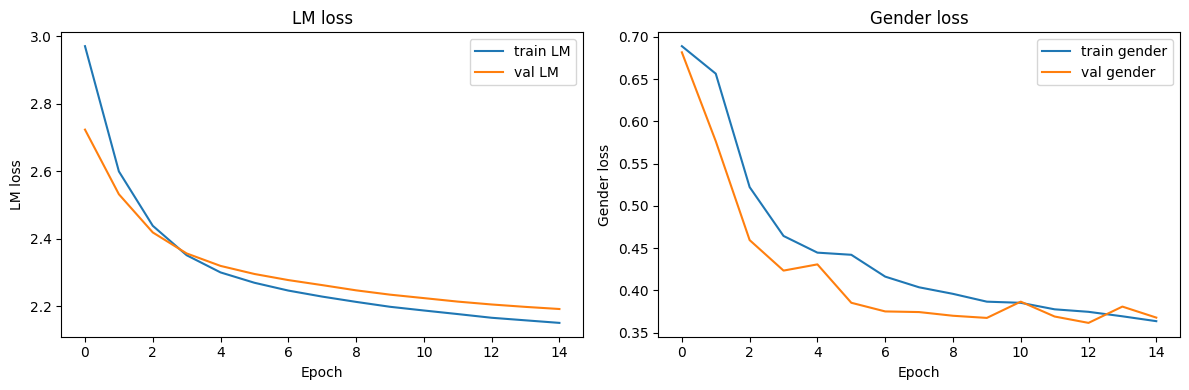

Multitask samples: ['kelli', 'alonn', 'donio', 'andella', 'elista', 'frissa', 'macele', 'maradus', 'buss', 'branda']
Multitask ROC AUC: 0.9066903852828877


In [37]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(hist_mt['train_lm'], label='train LM')
plt.plot(hist_mt['val_lm'], label='val LM')
plt.xlabel('Epoch'); plt.ylabel('LM loss'); plt.title('LM loss')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(hist_mt['train_g'], label='train gender')
plt.plot(hist_mt['val_g'], label='val gender')
plt.xlabel('Epoch'); plt.ylabel('Gender loss'); plt.title('Gender loss')
plt.legend()
plt.tight_layout(); plt.show()

print('Multitask samples:', generate_names(gru_mt, 10, temperature=0.8))
yt, yp = predict_gender_proba(gru_mt, test_loader)
print('Multitask ROC AUC:', roc_auc_score(yt, yp))

# Визуализация эмбеддингов

In [38]:
emb = gru_mt.emb.weight.detach().cpu().numpy()
tsne = TSNE(n_components=2, random_state=SEED, perplexity=10)
emb_tsne = tsne.fit_transform(emb)
pca = PCA(n_components=2, random_state=SEED)
emb_pca = pca.fit_transform(emb)

vowels = set('aeiou')
is_vowel = np.array([id2token[i] in vowels for i in range(vocab_size)])
labels = np.array([id2token[i] for i in range(vocab_size)])

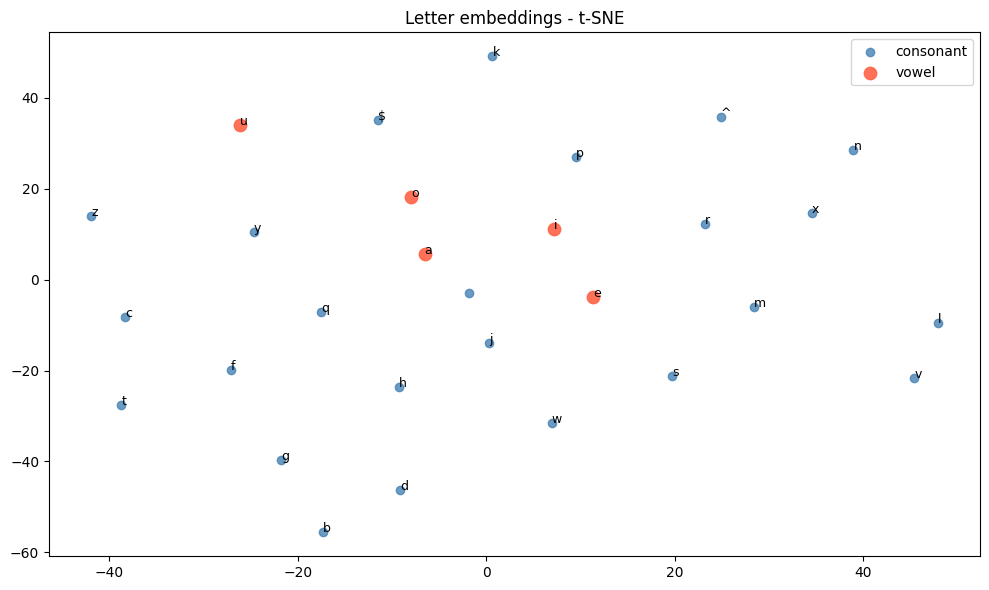

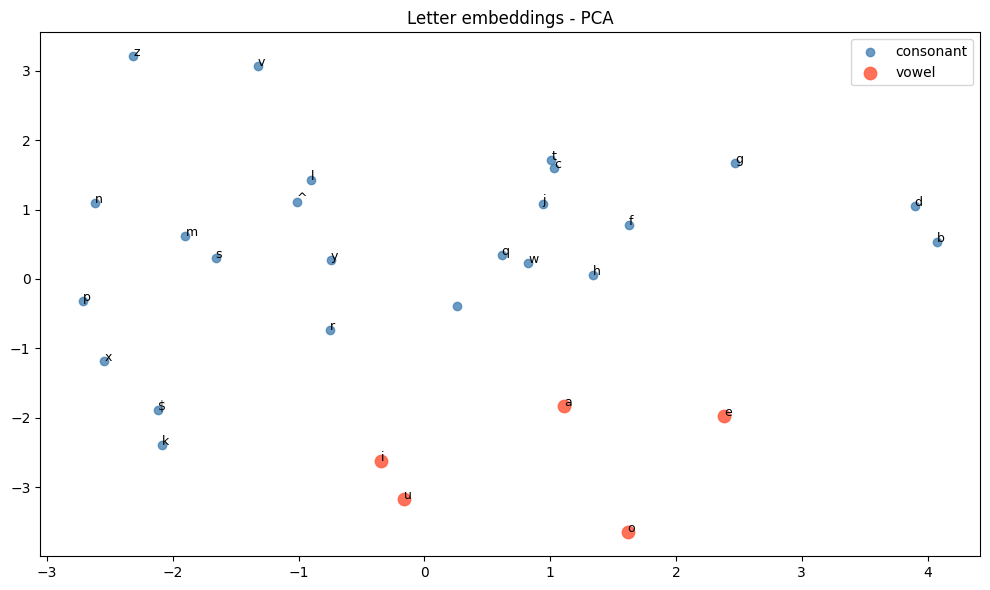

In [39]:
def plot_2d(coords, title):
    plt.figure(figsize=(10, 6))
    plt.scatter(coords[~is_vowel, 0], coords[~is_vowel, 1], c='steelblue', label='consonant', alpha=0.8)
    plt.scatter(coords[is_vowel, 0], coords[is_vowel, 1], c='tomato', label='vowel', alpha=0.9, s=80)
    for i, ch in enumerate(labels):
        plt.text(coords[i, 0], coords[i, 1], ch, fontsize=9)
    plt.title(title); plt.legend(); plt.tight_layout(); plt.show()

plot_2d(emb_tsne, 'Letter embeddings - t-SNE')
plot_2d(emb_pca, 'Letter embeddings - PCA')

### f) Какие выводы можно сделать?
Гласные и согласные буквы имеют тенденцию образовывать отдельные кластеры в обеих проекциях. Это означает, что пространство эмбеддингов улавливает различие между гласными и согласными, даже если модель никогда не получала такой информации явно. Буквы, которые часто встречаются вместе в схожих контекстах (например, распространенные сочетания согласных или пары гласных), располагаются близко друг к другу. Специальные токены (`<SOS>`, `<EOS>`, пробел) занимают обособленные позиции, поскольку выполняют уникальные распределительные роли. t-SNE делает акцент на локальных окрестностях и часто показывает более плотные кластеры; PCA захватывает глобальную дисперсию и, как правило, распределяет гласные вдоль доминирующей оси.